In [1]:
import pandas as pd
import numpy as np
import os

BASE_DIR = r"C:\Users\vikra\Desktop\Supply Chain Algo"

DATA_DIR = os.path.join(BASE_DIR, "Data")
PROCESSED_DIR = os.path.join(DATA_DIR, "processed")
REPORT_DIR = os.path.join(BASE_DIR, "reports")

os.makedirs(REPORT_DIR, exist_ok=True)

# Load future demand predictions
forecast_df = pd.read_csv(
    os.path.join(
        REPORT_DIR,
        "16_day_demand_forecast.csv"
    )
)

# Load historical sales
history_df = pd.read_csv(
    os.path.join(
        PROCESSED_DIR,
        "sales_clean.csv"
    )
)

forecast_df["date"] = pd.to_datetime(
    forecast_df["date"]
)

history_df["date"] = pd.to_datetime(
    history_df["date"]
)

print("Forecast Shape:", forecast_df.shape)
print("Historical Shape:", history_df.shape)

display(forecast_df.head())

Forecast Shape: (28512, 6)
Historical Shape: (3000888, 21)


,id,date,store_nbr,family,onpromotion,predicted_sales
0,3000888,2017-08-16,1,AUTOMOTIVE,0,3.971071
1,3000889,2017-08-16,1,BABY CARE,0,0.030084
2,3000890,2017-08-16,1,BEAUTY,2,4.548280
3,3000891,2017-08-16,1,BEVERAGES,20,2014.342667
4,3000892,2017-08-16,1,BOOKS,0,0.038141


In [23]:
forecast_df.head()
forecast_df.tail()

forecast_df['onpromotion'].unique()

array([  0,   2,   1,  20,  17,  12,  11,  10,  14,   9,  27,  26,  32,
        23,  31,  35,  33,   7,   5,   6,   3,   4,  25,   8,  13,  45,
        18,  22,  16,  52,  64,  24,  41,  44,  50,  48,  47,  65,  67,
        49,  36, 256, 211, 208,  15,  38,  34,  39,  21,  19,  66,  57,
        30,  29,  37,  55,  61,  56,  73,  75,  43,  42, 255, 212, 214,
        70,  69,  60,  40,  68,  93,  53,  46, 254, 228, 229,  28,  58,
        62,  77, 253, 182, 184,  59,  83,  71, 171, 170,  63,  78, 252,
       191, 189,  81,  89,  82,  51, 237, 236,  74, 154, 138, 146,  94,
        91, 158, 141, 165, 106,  96,  54, 490, 230, 145, 128, 122, 102,
        87, 163, 133, 115,  92, 103, 219,  86, 107,  79,  90, 244, 114,
        88, 223,  98,  95, 105,  97, 217, 108,  84, 494, 139, 118, 123,
       177, 116, 117, 161, 140, 129,  72, 156, 144, 220,  76, 150, 132,
       178, 148, 124, 125,  80, 100, 203, 180, 210, 218, 151, 155,  85,
       101, 175, 152, 131, 143, 104, 168, 137, 136, 110, 205, 11

In [2]:
print(forecast_df.columns.tolist())
print(history_df.columns.tolist())

['id', 'date', 'store_nbr', 'family', 'onpromotion', 'predicted_sales']
['id', 'date', 'store_nbr', 'family', 'sales', 'onpromotion', 'city', 'state', 'type', 'cluster', 'dcoilwtico', 'transactions', 'has_holiday_event', 'holiday_event_count', 'year', 'month', 'day', 'day_of_week', 'week_of_year', 'quarter', 'is_weekend']


In [3]:
history_df["sales"] = pd.to_numeric(
    history_df["sales"],
    errors="coerce"
)

history_df = history_df.dropna(
    subset=[
        "date",
        "store_nbr",
        "family",
        "sales"
    ]
).copy()

latest_date = history_df["date"].max()

cutoff_date = (
    latest_date - pd.Timedelta(days=89)
)

recent_history = history_df[
    history_df["date"] >= cutoff_date
].copy()

In [4]:
demand_stats = (
    recent_history
    .groupby(["store_nbr", "family"])["sales"]
    .agg(
        historical_avg_demand="mean",
        historical_std_demand="std",
        historical_max_demand="max"
    )
    .reset_index()
)

demand_stats["historical_std_demand"] = (
    demand_stats["historical_std_demand"].fillna(0)
)

display(demand_stats.head(10))

,store_nbr,family,historical_avg_demand,historical_std_demand,historical_max_demand
0,1,AUTOMOTIVE,4.444444,3.141284,19.000
1,1,BABY CARE,0.000000,0.000000,0.000
2,1,BEAUTY,3.366667,2.164317,11.000
3,1,BEVERAGES,2165.566667,545.601391,2977.000
4,1,BOOKS,0.288889,0.640303,3.000
5,1,BREAD/BAKERY,341.545023,91.428386,481.324
6,1,CELEBRATION,14.588889,9.330263,46.000
7,1,CLEANING,645.200000,202.056962,944.000
8,1,DAIRY,684.355556,173.602045,957.000
9,1,DELI,129.672067,36.956826,217.501


In [17]:
display(
    inventory_inputs.reset_index(drop=True).head(10)
)

print(inventory_inputs.columns.tolist())


,store_nbr,family,on_hand_units,on_order_units,backorder_units,lead_time_days,review_period_days,service_level
0,1,AUTOMOTIVE,NaN,NaN,0,3,7,0.95
1,1,BABY CARE,NaN,NaN,0,3,7,0.95
2,1,BEAUTY,NaN,NaN,0,3,7,0.95
3,1,BEVERAGES,NaN,NaN,0,3,7,0.95
4,1,BOOKS,NaN,NaN,0,3,7,0.95
5,1,BREAD/BAKERY,NaN,NaN,0,3,7,0.95
6,1,CELEBRATION,NaN,NaN,0,3,7,0.95
7,1,CLEANING,NaN,NaN,0,3,7,0.95
8,1,DAIRY,NaN,NaN,0,3,7,0.95
9,1,DELI,NaN,NaN,0,3,7,0.95


['store_nbr', 'family', 'on_hand_units', 'on_order_units', 'backorder_units', 'lead_time_days', 'review_period_days', 'service_level']


In [18]:
inventory_path = os.path.join(
    DATA_DIR,
    "processed",
    "inventory_inputs_template.csv"
)

inventory_inputs.to_csv(
    inventory_path,
    index=False
)

print("Template saved:", inventory_path)

Template saved: C:\Users\vikra\Desktop\Supply Chain Algo\Data\processed\inventory_inputs_template.csv


In [19]:
inventory_inputs = (
    forecast_df[
        ["store_nbr", "family"]
    ]
    .drop_duplicates()
    .copy()
)

# Inventory information to be supplied by the business
inventory_inputs["on_hand_units"] = np.nan
inventory_inputs["on_order_units"] = np.nan
inventory_inputs["backorder_units"] = 0

# Illustrative assumptions only.
# Replace these with actual supplier and review schedules.
inventory_inputs["lead_time_days"] = 3
inventory_inputs["review_period_days"] = 7

inventory_inputs["service_level"] = 0.95

inventory_path = os.path.join(
    DATA_DIR,
    "processed",
    "inventory_inputs_template.csv"
)

inventory_inputs.to_csv(
    inventory_path,
    index=False
)

print("Inventory input template saved!")
print(inventory_path)

display(inventory_inputs.head())

Inventory input template saved!
C:\Users\vikra\Desktop\Supply Chain Algo\Data\processed\inventory_inputs_template.csv


,store_nbr,family,on_hand_units,on_order_units,backorder_units,lead_time_days,review_period_days,service_level
0,1,AUTOMOTIVE,NaN,NaN,0,3,7,0.95
1,1,BABY CARE,NaN,NaN,0,3,7,0.95
2,1,BEAUTY,NaN,NaN,0,3,7,0.95
3,1,BEVERAGES,NaN,NaN,0,3,7,0.95
4,1,BOOKS,NaN,NaN,0,3,7,0.95


In [6]:
Z_SCORE = 1.645

example_std = 20
example_lead_time = 3

example_safety_stock = (
    Z_SCORE
    * example_std
    * np.sqrt(example_lead_time)
)

print(
    "Example Safety Stock:",
    round(example_safety_stock, 2)
)

Example Safety Stock: 56.98


In [7]:
forecast_df = forecast_df.sort_values(
    ["store_nbr", "family", "date"]
).copy()

def calculate_lead_time_demand(group, lead_time):

    return group.head(lead_time)[
        "predicted_sales"
    ].sum()

In [8]:
example_forecast = 500
example_safety_stock = 57

reorder_point = (
    example_forecast
    + example_safety_stock
)

print("Reorder Point:", reorder_point)

Reorder Point: 557


In [9]:
inventory_data = inventory_inputs.merge(
    demand_stats,
    on=["store_nbr", "family"],
    how="left"
)

print("Inventory combinations:", inventory_data.shape)

display(inventory_data.head())

Inventory combinations: (1782, 11)


,store_nbr,family,on_hand_units,on_order_units,backorder_units,lead_time_days,review_period_days,service_level,historical_avg_demand,historical_std_demand,historical_max_demand
0,1,AUTOMOTIVE,NaN,NaN,0,3,7,0.95,4.444444,3.141284,19.0
1,1,BABY CARE,NaN,NaN,0,3,7,0.95,0.000000,0.000000,0.0
2,1,BEAUTY,NaN,NaN,0,3,7,0.95,3.366667,2.164317,11.0
3,1,BEVERAGES,NaN,NaN,0,3,7,0.95,2165.566667,545.601391,2977.0
4,1,BOOKS,NaN,NaN,0,3,7,0.95,0.288889,0.640303,3.0


In [10]:
def calculate_inventory_metrics(row):

    store = row["store_nbr"]
    family = row["family"]

    group = forecast_df[
        (forecast_df["store_nbr"] == store) &
        (forecast_df["family"] == family)
    ].sort_values("date")

    lead_time = int(row["lead_time_days"])
    review_period = int(row["review_period_days"])

    service_level = float(row["service_level"])

    z_scores = {
        0.90: 1.282,
        0.95: 1.645,
        0.975: 1.960,
        0.99: 2.326
    }

    if service_level not in z_scores:
        raise ValueError("Unsupported service level.")

    z = z_scores[service_level]

    if lead_time < 1 or review_period < 0:
        raise ValueError("Invalid lead time or review period.")

    if lead_time + review_period > len(group):
        return pd.Series({
            "reorder_point": np.nan,
            "order_up_to_level": np.nan,
            "safety_stock": np.nan,
            "forecast_lead_time_demand": np.nan,
            "recommended_order_qty": np.nan,
            "inventory_status": "Forecast horizon too short"
        })

    daily_std = row["historical_std_demand"]

    if pd.isna(daily_std):
        daily_std = 0

    # Demand during lead time
    lead_demand = group.head(lead_time)[
        "predicted_sales"
    ].sum()

    # Safety stock during lead time
    lead_safety_stock = (
        z * daily_std * np.sqrt(lead_time)
    )

    # Reorder point
    reorder_point = (
        lead_demand + lead_safety_stock
    )

    # Demand over lead time + review period
    protection_period = lead_time + review_period

    protection_demand = group.head(
        protection_period
    )["predicted_sales"].sum()

    # Safety stock over protection period
    protection_safety_stock = (
        z * daily_std * np.sqrt(protection_period)
    )

    # Order-up-to target
    order_up_to_level = (
        protection_demand + protection_safety_stock
    )

    # Current inventory position
    on_hand = row["on_hand_units"]
    on_order = row["on_order_units"]
    backorders = row["backorder_units"]

    if pd.isna(on_hand) or pd.isna(on_order):
        inventory_position = np.nan
        recommended_order_qty = np.nan
        status = "Inventory data required"

    else:
        inventory_position = (
            on_hand + on_order - backorders
        )

        recommended_order_qty = max(
            np.ceil(
                order_up_to_level - inventory_position
            ),
            0
        )

        status = (
            "REORDER"
            if inventory_position <= reorder_point
            else "Stock sufficient for lead time"
        )

    return pd.Series({
        "forecast_lead_time_demand": lead_demand,
        "safety_stock": lead_safety_stock,
        "reorder_point": reorder_point,
        "forecast_protection_demand": protection_demand,
        "order_up_to_level": order_up_to_level,
        "inventory_position": inventory_position,
        "recommended_order_qty": recommended_order_qty,
        "inventory_status": status
    })

In [11]:
inventory_results = inventory_data.join(
    inventory_data.apply(
        calculate_inventory_metrics,
        axis=1
    )
)

display(inventory_results.head(20))

,store_nbr,family,on_hand_units,on_order_units,backorder_units,lead_time_days,review_period_days,service_level,historical_avg_demand,historical_std_demand,historical_max_demand,forecast_lead_time_demand,safety_stock,reorder_point,forecast_protection_demand,order_up_to_level,inventory_position,recommended_order_qty,inventory_status
0,1,AUTOMOTIVE,NaN,NaN,0,3,7,0.95,4.444444,3.141284,19.000,10.966438,8.950221,19.916659,33.197317,49.538109,NaN,NaN,Inventory data required
1,1,BABY CARE,NaN,NaN,0,3,7,0.95,0.000000,0.000000,0.000,0.045900,0.000000,0.045900,0.132995,0.132995,NaN,NaN,Inventory data required
2,1,BEAUTY,NaN,NaN,0,3,7,0.95,3.366667,2.164317,11.000,11.589085,6.166624,17.755709,33.650002,44.908666,NaN,NaN,Inventory data required
3,1,BEVERAGES,NaN,NaN,0,3,7,0.95,2165.566667,545.601391,2977.000,5462.321395,1554.540347,7016.861742,16882.569562,19720.758943,NaN,NaN,Inventory data required
4,1,BOOKS,NaN,NaN,0,3,7,0.95,0.288889,0.640303,3.000,0.069725,1.824365,1.894090,0.191098,3.521918,NaN,NaN,Inventory data required
5,1,BREAD/BAKERY,NaN,NaN,0,3,7,0.95,341.545023,91.428386,481.324,925.357948,260.499912,1185.857860,2786.455018,3262.060612,NaN,NaN,Inventory data required
6,1,CELEBRATION,NaN,NaN,0,3,7,0.95,14.588889,9.330263,46.000,30.114568,26.584005,56.698573,89.457164,137.992695,NaN,NaN,Inventory data required
7,1,CLEANING,NaN,NaN,0,3,7,0.95,645.200000,202.056962,944.000,1726.477114,575.705459,2302.182574,5055.440630,6106.530185,NaN,NaN,Inventory data required
8,1,DAIRY,NaN,NaN,0,3,7,0.95,684.355556,173.602045,957.000,1804.508589,494.631039,2299.139627,5449.832281,6352.900873,NaN,NaN,Inventory data required
9,1,DELI,NaN,NaN,0,3,7,0.95,129.672067,36.956826,217.501,390.378623,105.298260,495.676883,1226.587729,1418.835170,NaN,NaN,Inventory data required


In [12]:
inventory_results["inventory_risk"] = np.where(
    inventory_results["inventory_status"] == "REORDER",
    "High Priority",
    np.where(
        inventory_results["inventory_status"] == "Stock sufficient for lead time",
        "Normal",
        "Pending Inventory Data"
    )
)

display(
    inventory_results[
        [
            "store_nbr",
            "family",
            "inventory_position",
            "reorder_point",
            "recommended_order_qty",
            "inventory_risk"
        ]
    ].head(20)
)

,store_nbr,family,inventory_position,reorder_point,recommended_order_qty,inventory_risk
0,1,AUTOMOTIVE,NaN,19.916659,NaN,Pending Inventory Data
1,1,BABY CARE,NaN,0.045900,NaN,Pending Inventory Data
2,1,BEAUTY,NaN,17.755709,NaN,Pending Inventory Data
3,1,BEVERAGES,NaN,7016.861742,NaN,Pending Inventory Data
4,1,BOOKS,NaN,1.894090,NaN,Pending Inventory Data
5,1,BREAD/BAKERY,NaN,1185.857860,NaN,Pending Inventory Data
6,1,CELEBRATION,NaN,56.698573,NaN,Pending Inventory Data
7,1,CLEANING,NaN,2302.182574,NaN,Pending Inventory Data
8,1,DAIRY,NaN,2299.139627,NaN,Pending Inventory Data
9,1,DELI,NaN,495.676883,NaN,Pending Inventory Data


In [13]:
store_inventory = (
    inventory_results
    .groupby("store_nbr")
    .agg(
        total_recommended_order=(
            "recommended_order_qty",
            "sum"
        ),
        high_priority_categories=(
            "inventory_risk",
            lambda x: (x == "High Priority").sum()
        ),
        category_count=("family", "nunique")
    )
    .reset_index()
)

display(store_inventory.head(20))

,store_nbr,total_recommended_order,high_priority_categories,category_count
0,1,0.0,0,33
1,2,0.0,0,33
2,3,0.0,0,33
3,4,0.0,0,33
4,5,0.0,0,33
5,6,0.0,0,33
6,7,0.0,0,33
7,8,0.0,0,33
8,9,0.0,0,33
9,10,0.0,0,33


In [14]:
category_inventory = (
    inventory_results
    .groupby("family")
    .agg(
        total_recommended_order=(
            "recommended_order_qty",
            "sum"
        ),
        high_priority_stores=(
            "inventory_risk",
            lambda x: (x == "High Priority").sum()
        )
    )
    .reset_index()
    .sort_values(
        "total_recommended_order",
        ascending=False
    )
)

display(category_inventory.head(20))

,family,total_recommended_order,high_priority_stores
0,AUTOMOTIVE,0.0,0
1,BABY CARE,0.0,0
2,BEAUTY,0.0,0
3,BEVERAGES,0.0,0
4,BOOKS,0.0,0
5,BREAD/BAKERY,0.0,0
6,CELEBRATION,0.0,0
7,CLEANING,0.0,0
8,DAIRY,0.0,0
9,DELI,0.0,0


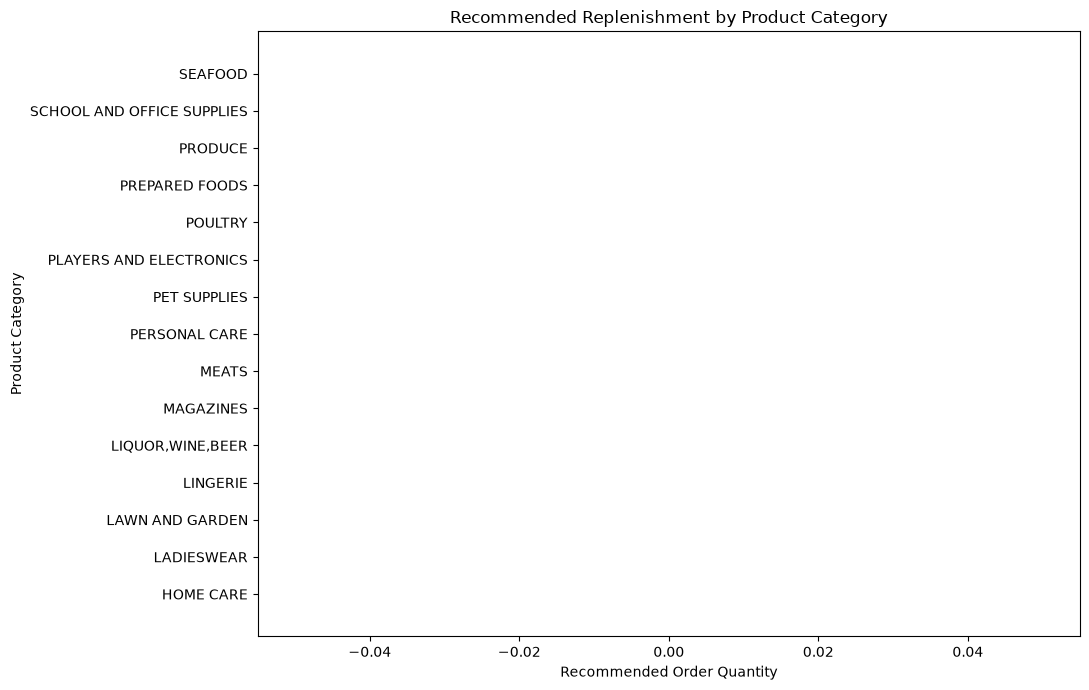

In [15]:
import matplotlib.pyplot as plt

plot_data = category_inventory.sort_values(
    "total_recommended_order",
    ascending=True
).tail(15)

plt.figure(figsize=(11, 7))

plt.barh(
    plot_data["family"],
    plot_data["total_recommended_order"]
)

plt.title("Recommended Replenishment by Product Category")
plt.xlabel("Recommended Order Quantity")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [16]:
inventory_results.to_csv(
    os.path.join(
        REPORT_DIR,
        "inventory_optimization_results.csv"
    ),
    index=False
)

store_inventory.to_csv(
    os.path.join(
        REPORT_DIR,
        "store_inventory_summary.csv"
    ),
    index=False
)

category_inventory.to_csv(
    os.path.join(
        REPORT_DIR,
        "category_inventory_summary.csv"
    ),
    index=False
)

print("Inventory optimization reports saved successfully!")

Inventory optimization reports saved successfully!
